# ODMR Notebook
You can use this notebook to do Optically Detected Magnetic Resonance (ODMR) measurements on the Room Temperature NV setup. The idea behind such a measurement is that you see the dependence of the emission rate of the NV center on the frequency of a microwave electric signal that is transmitted close to the NV center. To do this, the measurement controls two main instruments:
1. **The DAC**: The National Instruments (NI) Digital-to-Analog Converter (DAC) is used to readout the amount of photons emitted by the NV center. It is hooked up to the output of the Avalanche Photo Detectors and counts the number of detected photons within a specified time interval. By default, it runs on a 10Hz clock.
2. **The RF Source**: This instrument generates the microwave signal that is transmitted close to the NV center. Using the specified functions, you can change the frequency of the signal it outputs, as well as it's amplitude (in a log-scale unit: the dBm; see: https://en.wikipedia.org/wiki/DBm).

By controlling these two instruments, you will write an ODMR measurement in the code below. To help you get started, some functions are pre-defined:
1. `init_equipment()` prepares the DAC and RF source such that their functionalities become available. This function should be ran once, right after starting a `QMI environment`. The function outputs the DAC and RF source objects.
2. `set_microwave_frequency(rf_source, mw_frequency_hz)` a function with which you can change the microwave frequency that the RF source outputs. It's inputs are the RF source Python object and the desired microwave frequency in Hz.
3. `set_microwave_power(rf_source, mw_power_dbm)` a function with which you can change the microwave power that the RF sourc outputs. It's inputs are the RF source Python object and the desired microwave power in dBm.
4. `get_count_array(dac, nof_samples)` a function that outputs an array with length `nof_samples` containing the number of counted photons, expressed as *photons per second*.
5. `save_dataset(dataset, name)` a function that saves your xarray Dataset in the data folder with the specified name.
6. `load_dataset(name)` a function that loads a saved xarray Dataset from the data folder with the specified name.

In the cells below, we've setup a framework for you to write your own code in.

In [1]:
import os
import numpy as np
import xarray as xr
from lmfit.models import LorentzianModel, LinearModel
from lmfit.models import VoigtModel, ConstantModel
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

def fit_two_peaks(dataset, fit_window=50e+6, relative_prominence=0.5):
    x = dataset.mw_frequency.values
    y_raw = dataset.photon_counts.values
    y_min = np.min(y_raw)
    y_max = np.max(y_raw)   
    y_cor = (y_raw - y_min) / (y_max - y_min)
    a, b = np.polyfit(x, y_cor, 1)
    trend = a*x + b
    y = y_cor - a*(x - np.mean(x))

    model = ConstantModel()
    params = model.guess(y, x)
    params['c'].set(min=0, max=1)
    peaks, _ = find_peaks(1-y, prominence=(np.max(y) - np.min(y))*relative_prominence)
    peak_heights = (1-y)[peaks]
    peaks_sorted_limited = peaks[np.argsort(peak_heights)][-2:]
    peaks_to_fit = np.sort(peaks_sorted_limited)

    for i, peak in enumerate(peaks_to_fit):
        freq_peak = x[peak]
        peak_slice = dataset.sel(
            mw_frequency=slice(freq_peak-fit_window/2, freq_peak+fit_window/2)
        )
        freqs = peak_slice.mw_frequency.values
        counts = peak_slice.photon_counts.values
        peak_model = VoigtModel(prefix=f"peak_{i}_")
        params.update(peak_model.guess(counts, freqs))
        params[f"peak_{i}_amplitude"].set(min=0)
        model -= peak_model

    result = model.fit(y, params=params, x=x)

    return result

# def data_correction(dataset):
#     begavg = dataset["photon_counts"][1:10].mean()
#     endavg = dataset["photon_counts"][len(dataset["mw_frequency"])-10:len(dataset["mw_frequency"])].mean()
#     ang = np.arctan((endavg - begavg) / (dataset["mw_frequency"][len(dataset["mw_frequency"])-1] - dataset["mw_frequency"][1]))
#     cor_data = dataset["photon_counts"] * np.cos(ang) + dataset["mw_frequency"] * np.sin(-ang)
#     cor_data -= np.abs(dataset["photon_counts"][0] - cor_data[0])
#     return cor_data

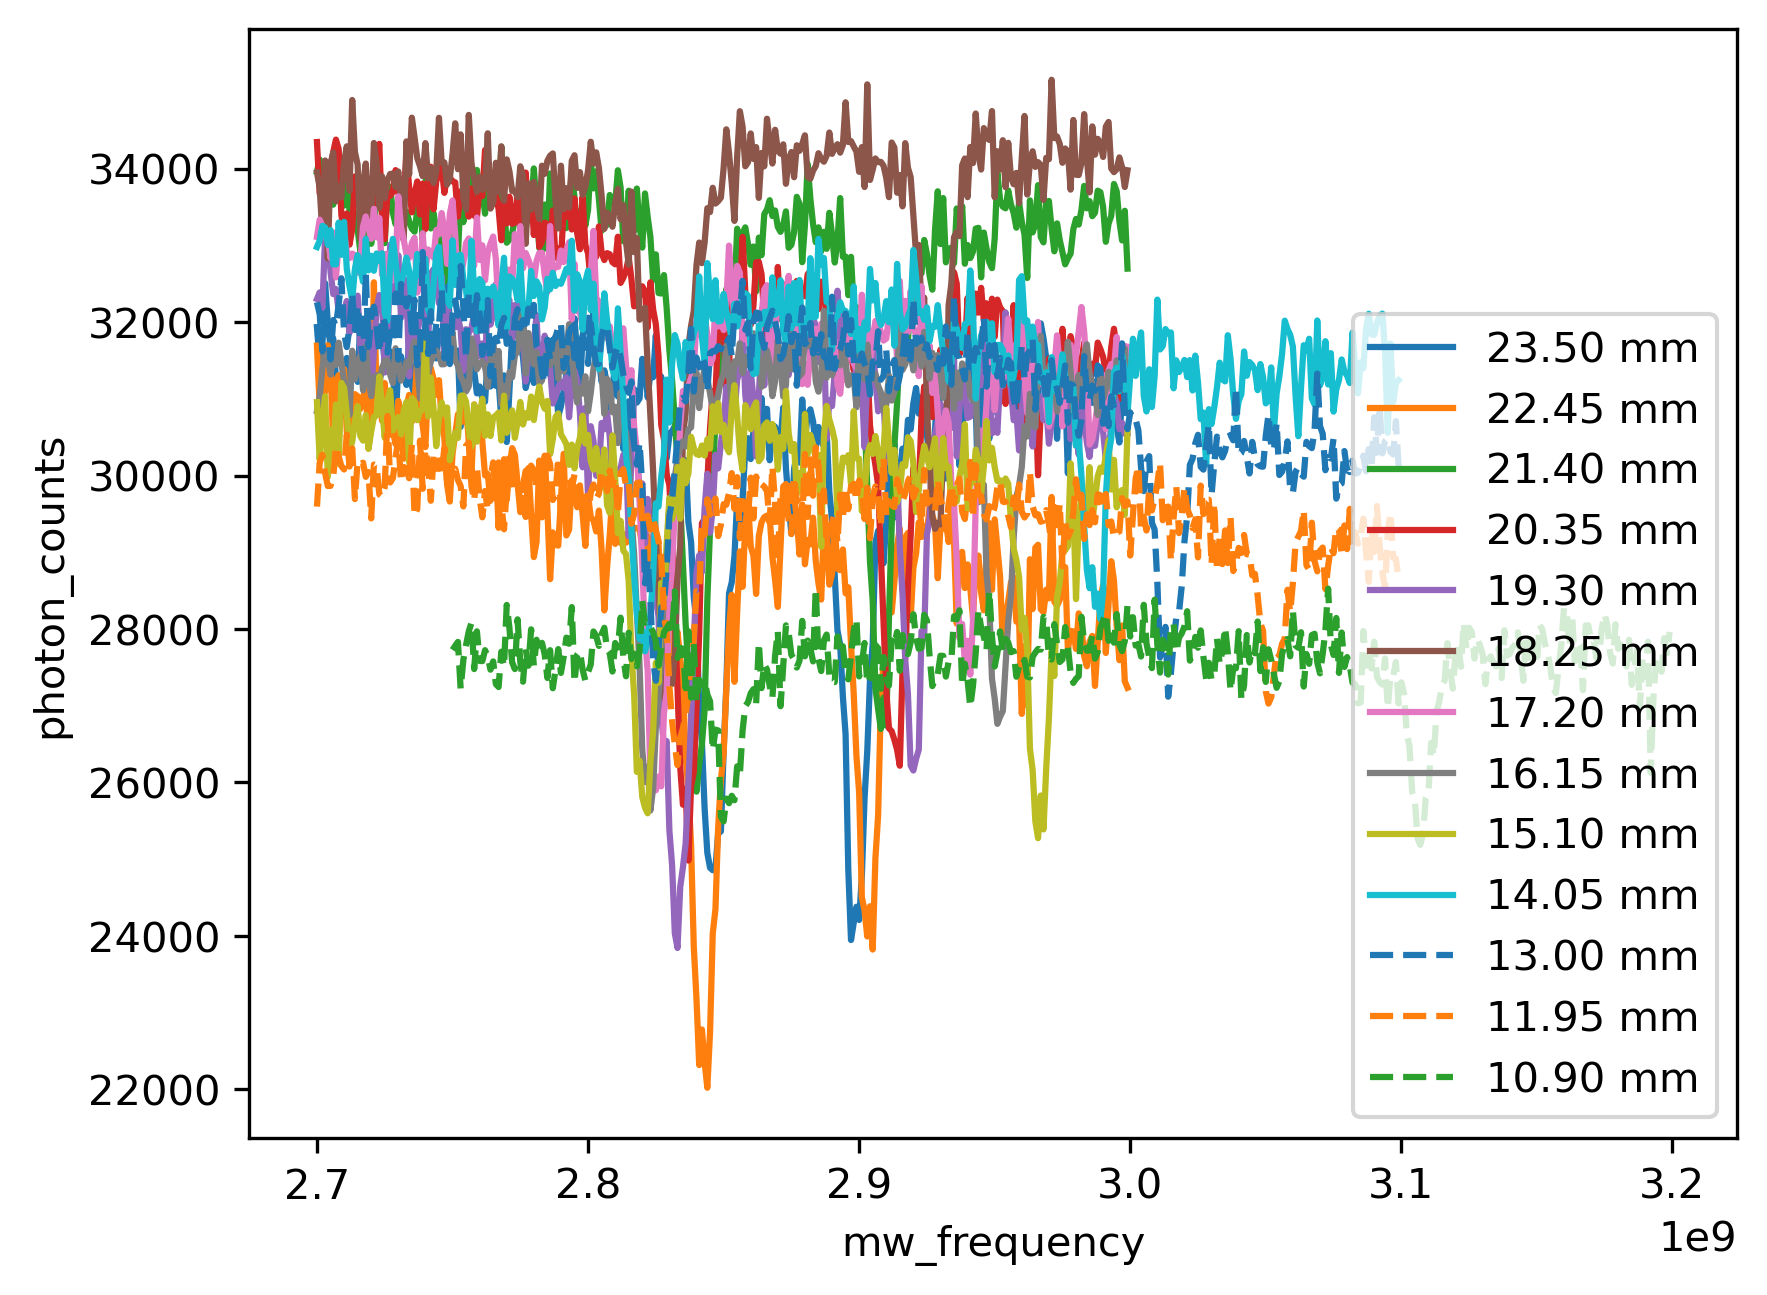

In [2]:
# Some required imports, please don't remove anything here. Feel free to add imports
import qmi
import os
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

def load_dataset(name):
      return xr.load_dataset(f"Data/{name}.hdf5", engine="h5netcdf")

plt.figure(dpi=300)
data1 = load_dataset("Set_Magneet_0rot")
data1.photon_counts.plot(label=f"{23.5 - 0 * 0.35:.2f} mm")
data2 = load_dataset("Set_Magneet_3rot")
data2.photon_counts.plot(label=f"{23.5 - 3 * 0.35:.2f} mm")
data3 = load_dataset("Set_Magneet_6rot")
data3.photon_counts.plot(label=f"{23.5 - 6 * 0.35:.2f} mm")
data4 = load_dataset("Set_Magneet_9rot")
data4.photon_counts.plot(label=f"{23.5 - 9 * 0.35:.2f} mm")
data5 = load_dataset("Set_Magneet_12rot")
data5.photon_counts.plot(label=f"{23.5 - 12 * 0.35:.2f} mm")
data6 = load_dataset("Set_Magneet_15rot")
data6.photon_counts.plot(label=f"{23.5 - 15 * 0.35:.2f} mm")
data7 = load_dataset("Set_Magneet_18rot")
data7.photon_counts.plot(label=f"{23.5 - 18 * 0.35:.2f} mm")
data8 = load_dataset("Set_Magneet_21rot")
data8.photon_counts.plot(label=f"{23.5 - 21 * 0.35:.2f} mm")
data9 = load_dataset("Set_Magneet_24rot")
data9.photon_counts.plot(label=f"{23.5 - 24 * 0.35:.2f} mm")
data10 = load_dataset("Set_Magneet_27rot")
data10.photon_counts.plot(label=f"{23.5 - 27 * 0.35:.2f} mm")
data11 = load_dataset("Set_Magneet_30rot")
data11.photon_counts.plot(label=f"{23.5 - 30 * 0.35:.2f} mm", linestyle="--")
data12 = load_dataset("Set_Magneet_33rot")
data12.photon_counts.plot(label=f"{23.5 - 33 * 0.35:.2f} mm", linestyle="--")
data13 = load_dataset("Set_Magneet_36rot")
data13.photon_counts.plot(label=f"{23.5 - 36 * 0.35:.2f} mm", linestyle="--")
plt.legend()
plt.show()

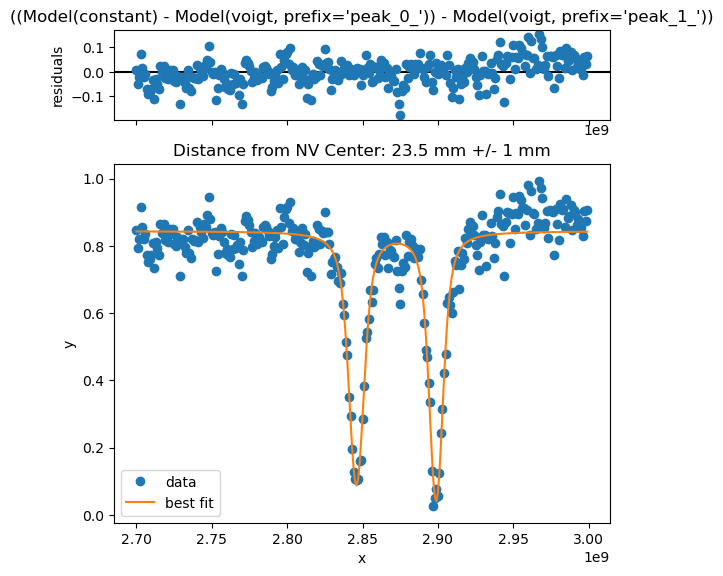

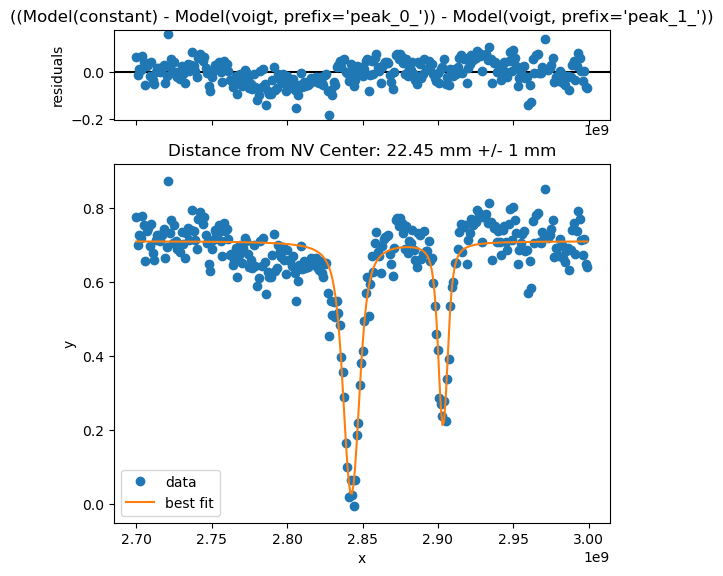

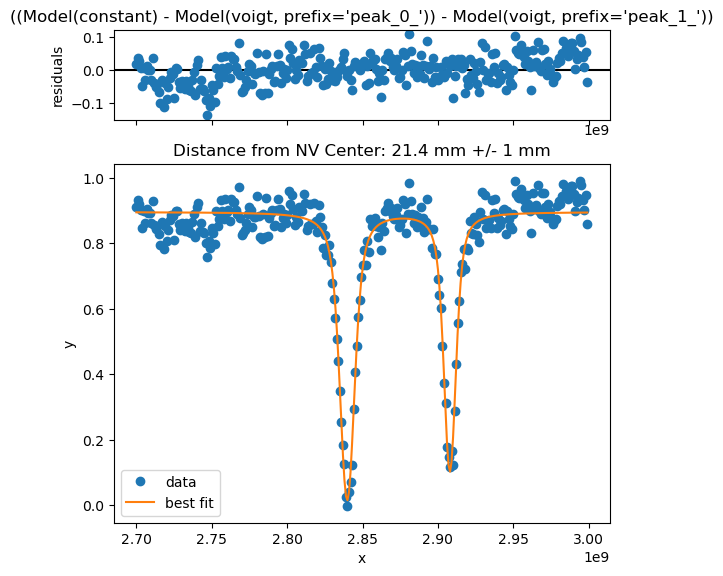

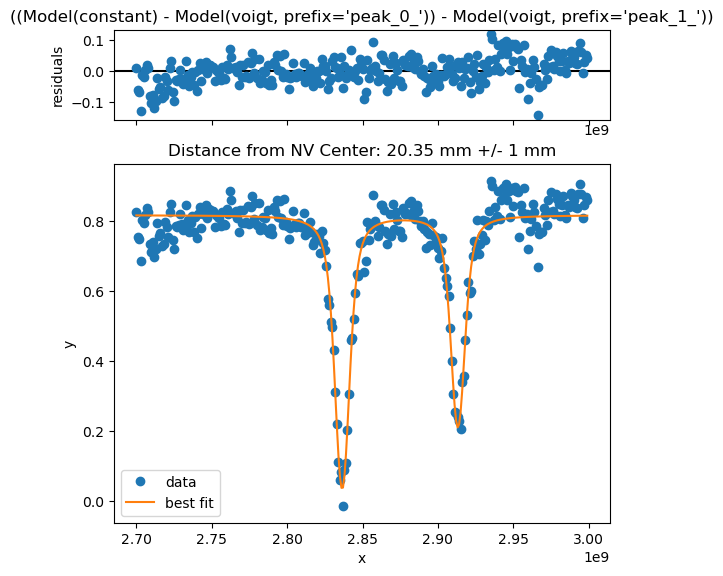

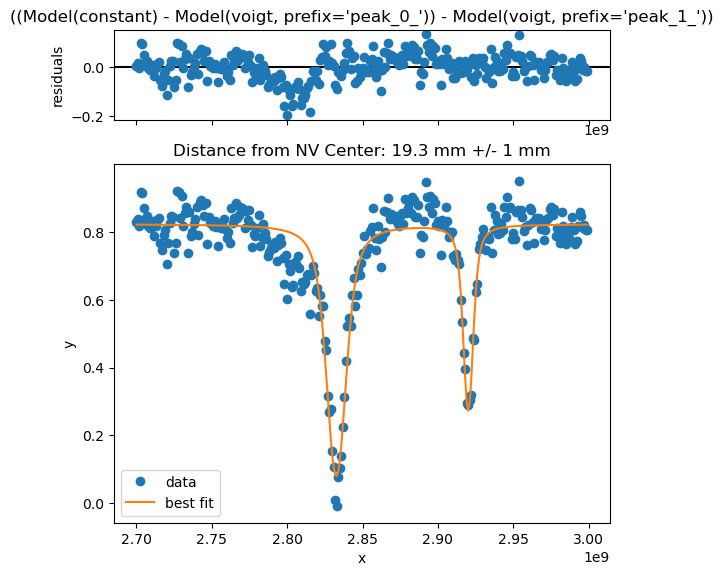

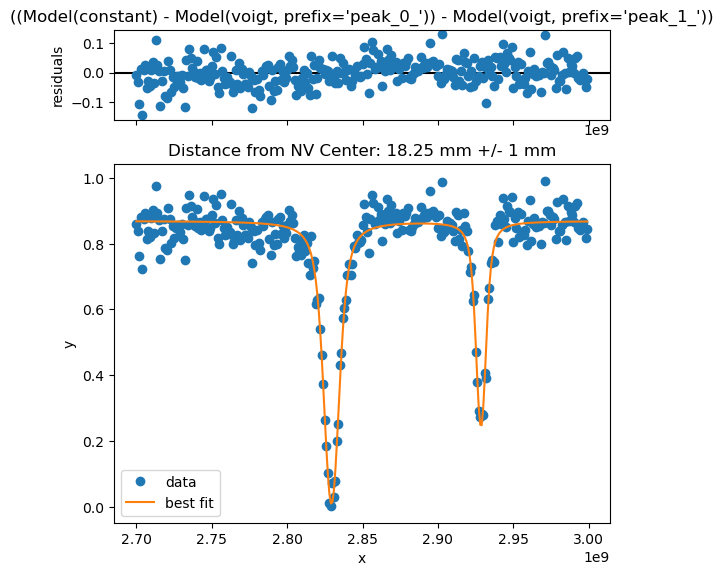

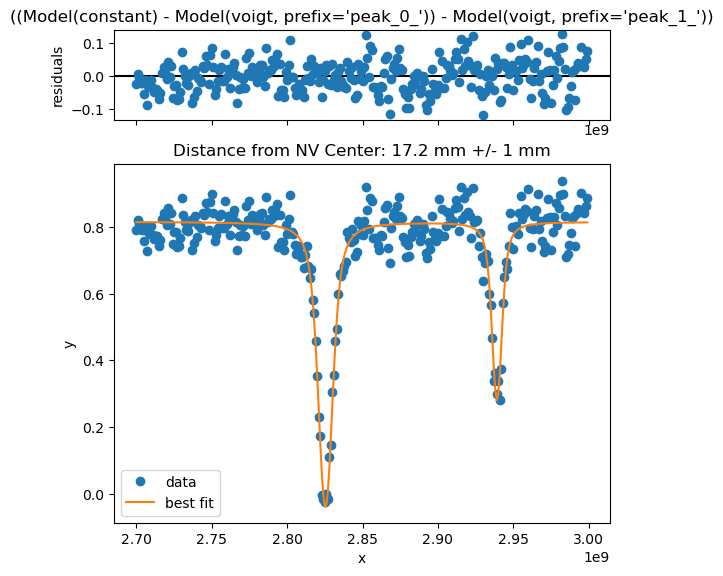

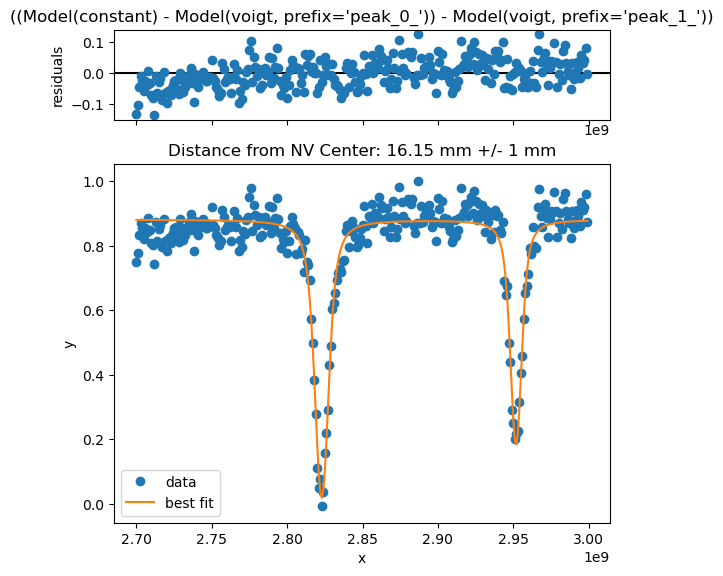

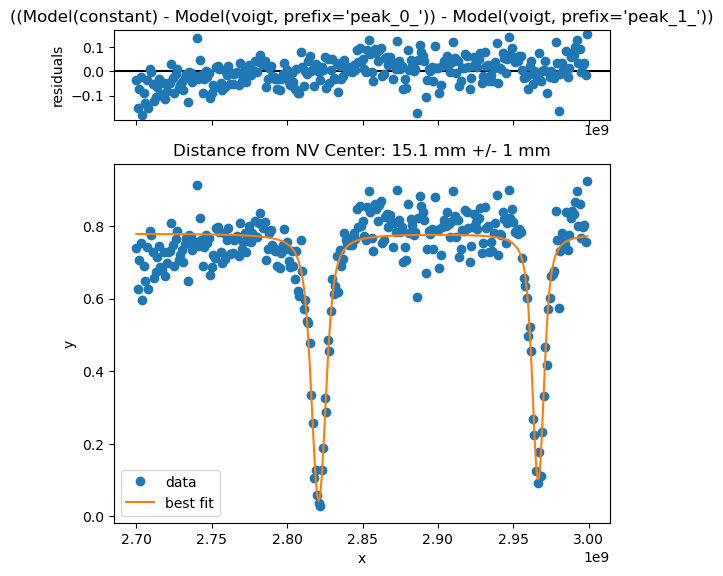

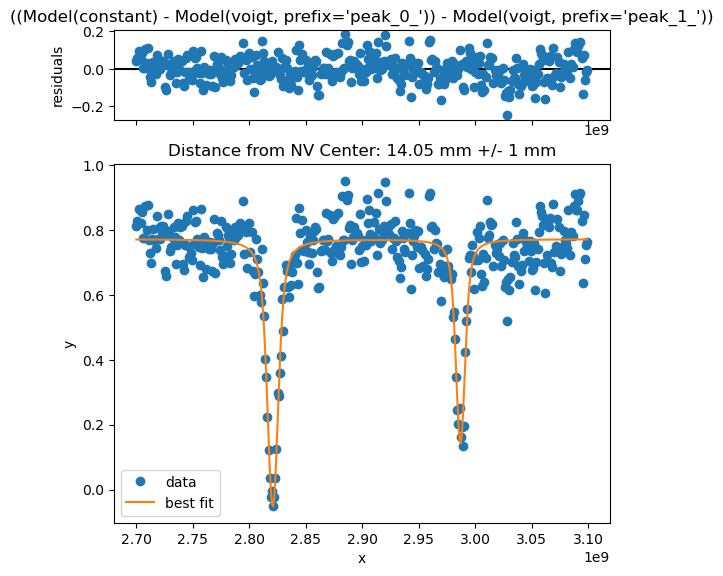

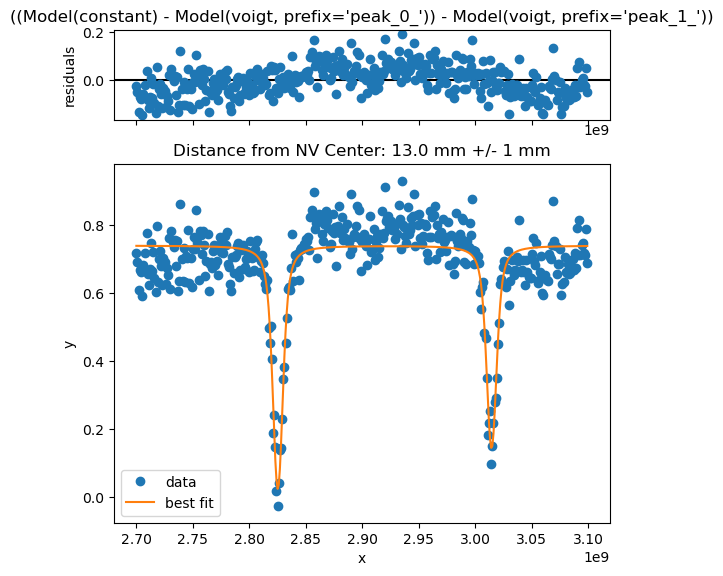

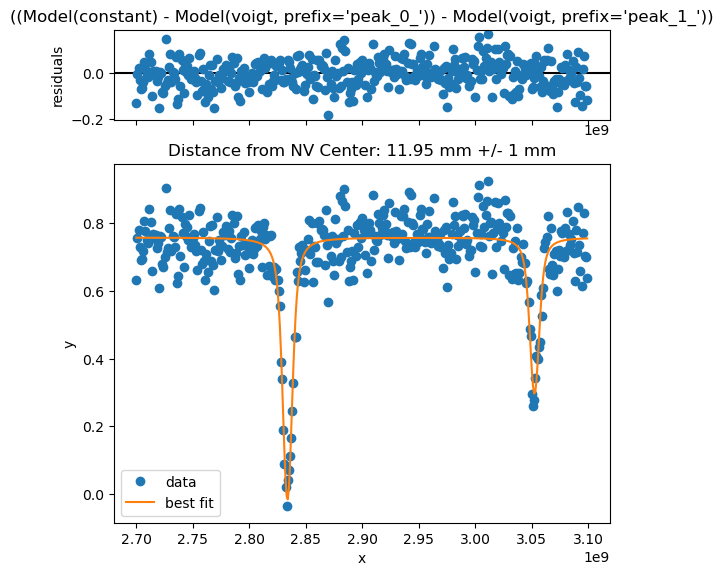

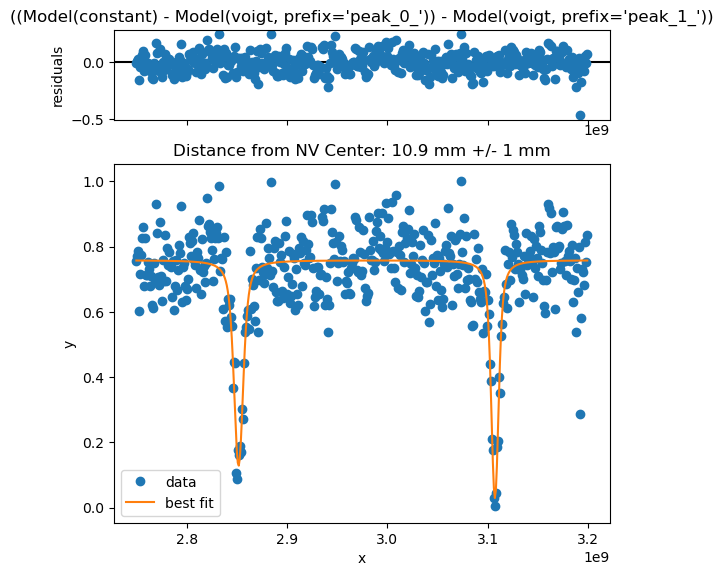

In [3]:
# f_u = f_1, f_l = f_2
f_u, f_l = np.array([]), np.array([])

for rot in range(0, 37, 3):
    Mag = xr.load_dataset(
        f"Data/Set_Magneet_{rot}rot.hdf5",
        engine="h5netcdf"
    )

    # result = Mag
    # cor_data = xr.Dataset() 
    # cor_data["mw_frequency"] = Mag["mw_frequency"]
    # cor_data["photon_counts"] = data_correction(Mag)
    result = fit_two_peaks(Mag)
    result.plot()
    plt.title(f"Distance from NV Center: {23.5 - 350*rot / 1000} mm +/- 1 mm")
    plt.show()

    f_u = np.append(f_u, result.params['peak_0_center'].value)
    f_l = np.append(f_l, result.params['peak_1_center'].value)

0.0
0.0
0.1025
0.1025


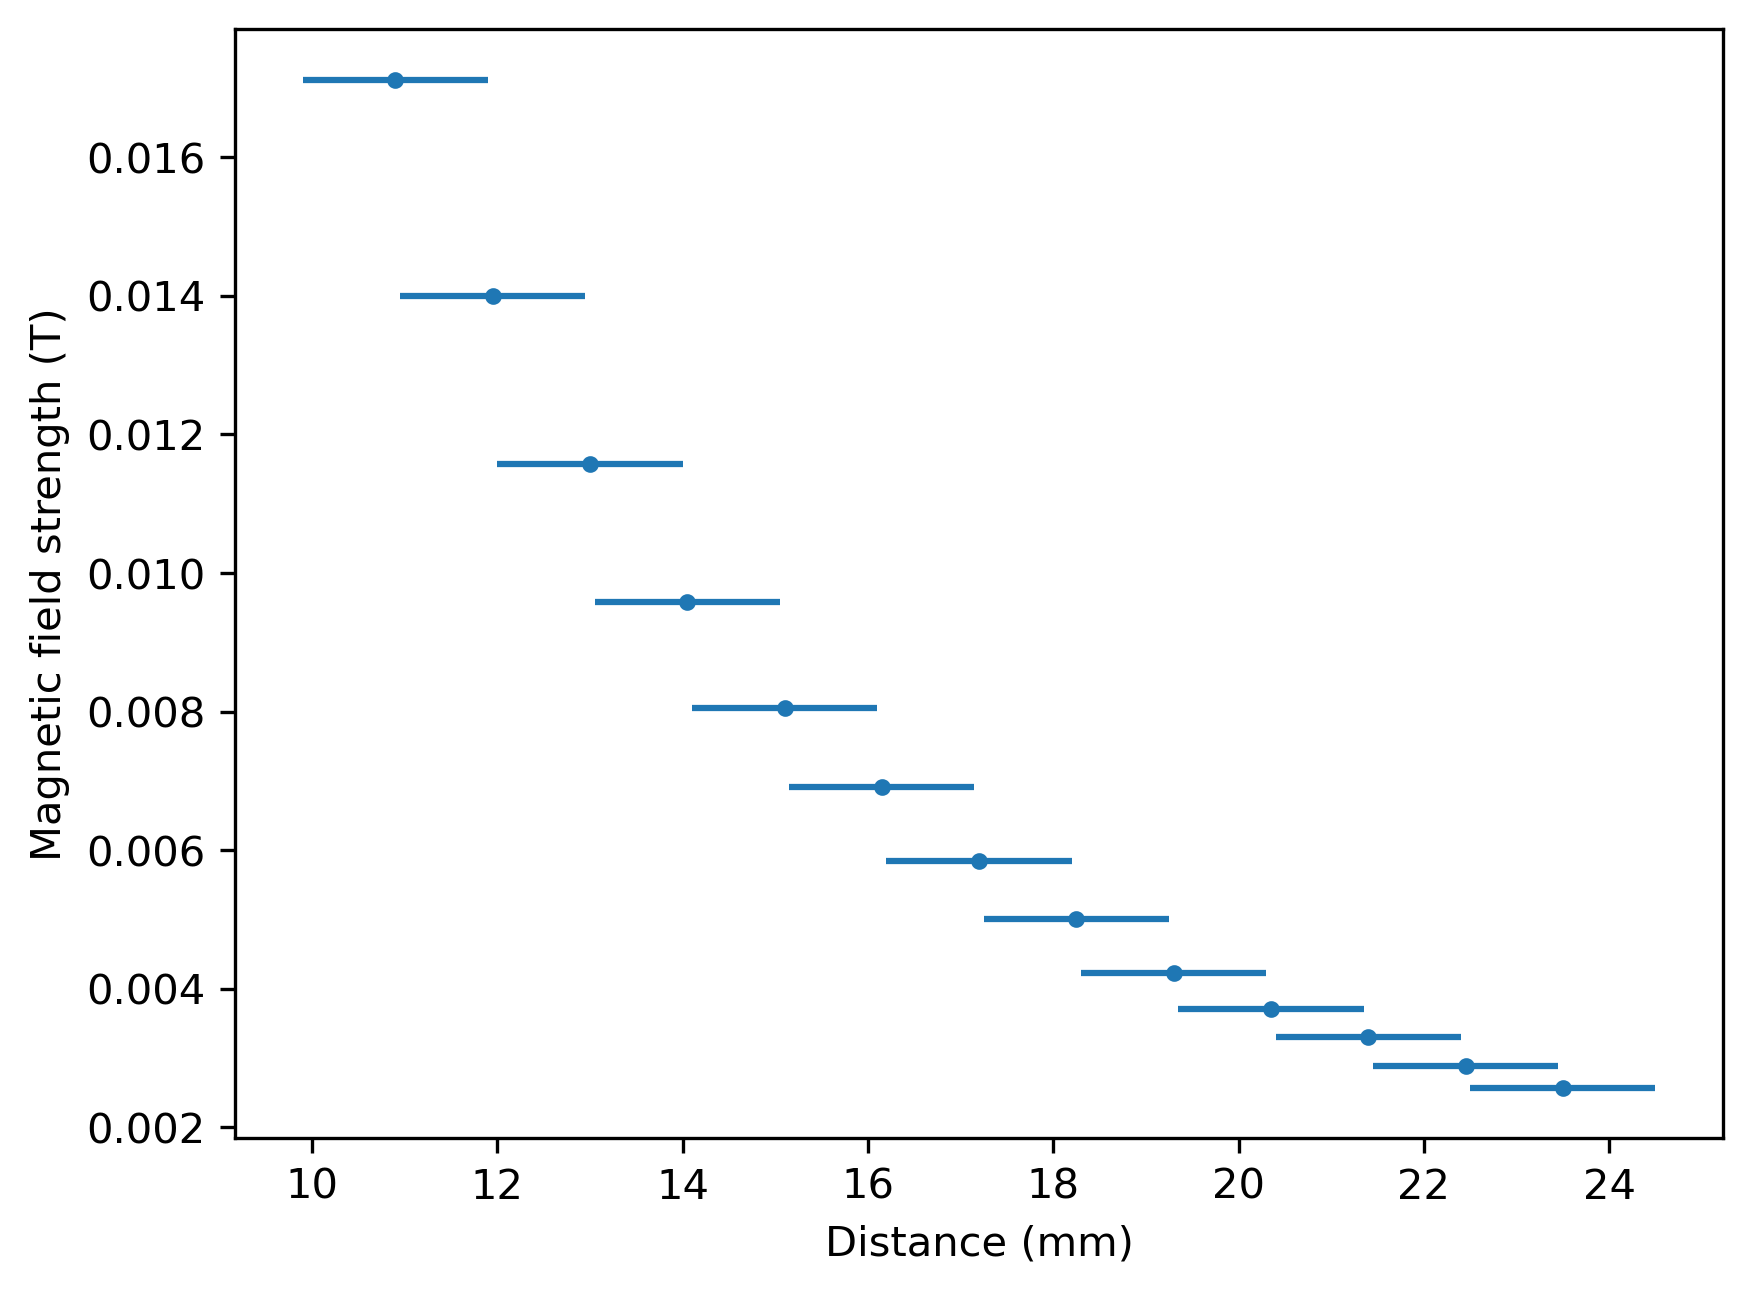

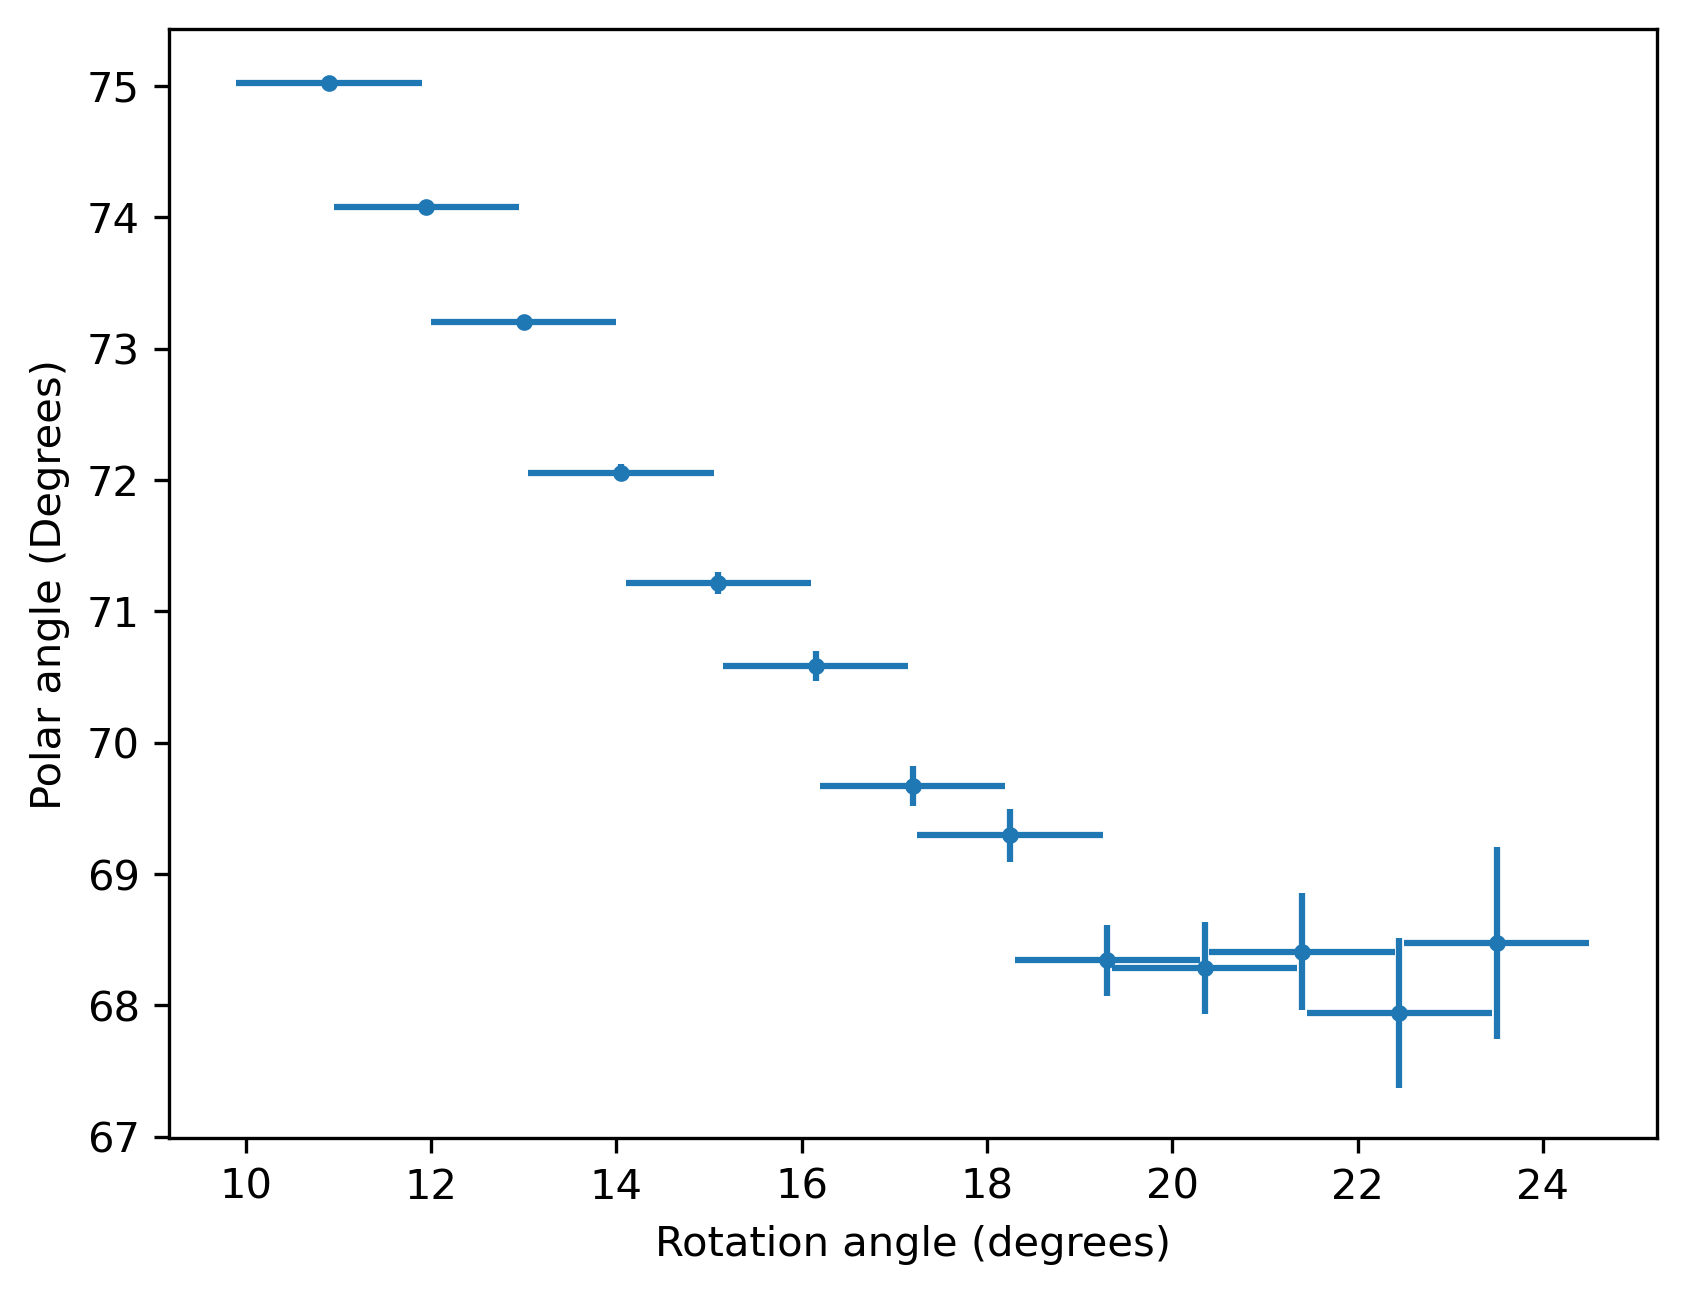

In [4]:
gam = 28e9 #Hz/T
D = 2.87e9 #Hz
rots = np.arange(0, 37, 3)
dist = 23.5 - 350*rots / 1000 #mm
u_dist = 1 #mm
u_theta = 0

def B(f1, f2):
    return np.sqrt((f1**2 + f2**2 - (f1 * f2) - D**2) / 3) / gam

# Uncertainties in B were insignificant (u ~ e-9, B ~ e-1)
def u_B(f1, f2, u_f1, u_f2, B):    
    return B * np.sqrt(((2 * f1 - f2) / (2 * np.sqrt((f1**2 + f2**2 - (f1 * f2) - D**2) * 3) * gam ))**2 * u_f1**2 + ((2 * f2 - f1) / (2 * np.sqrt((f1**2 + f2**2 - (f1 * f2) - D**2) * 3) * gam ))**2 * u_f2**2)

def theta(f1, f2, B):
    return np.arccos(np.sqrt(((-(f1 + f2)**3 + 3 * f1**3 + 3 * f2**3) / (27 * D * (gam * B)**2)) + (2 * D**2) / (27 * (gam * B)**2) + 1/3)) * 180 / np.pi

def u_theta(f1, f2, u_f1, u_f2, B):
    gB2 = (gam * B)**2
    return np.sqrt((((-(180/np.pi) / (18 * D * gB2 * np.sqrt(((-(f1 + f2)**3 + 3*f1**3 + 3*f2**3) / (27*D*gB2) + 2*D**2/(27*gB2) + 1/3) * (1 - ((-(f1 + f2)**3 + 3*f1**3 + 3*f2**3) / (27*D*gB2) + 2*D**2/(27*gB2) + 1/3))))) * (3*f1**2 - (f1 + f2)**2)) * u_f1)**2 + (((-(180/np.pi) / (18 * D * gB2 * np.sqrt(((-(f1 + f2)**3 + 3*f1**3 + 3*f2**3) / (27*D*gB2) + 2*D**2/(27*gB2) + 1/3) * (1 - ((-(f1 + f2)**3 + 3*f1**3 + 3*f2**3) / (27*D*gB2) + 2*D**2/(27*gB2) + 1/3))))) * (3*f2**2 - (f1 + f2)**2)) * u_f2)**2)

def BB(f1, f2, theta): # Equation for B based on the cos^2 equation
    return np.sqrt(((-(f1 + f2)**3 + 3 * f1**3 + 3 * f2**3) / (27 * D) + (2 * D**2) / 27) / ((np.cos(theta)**2 - 1/3) * gam**2))



B_values = B(f_u, f_l)
theta_values = theta(f_u, f_l, B_values)

B_theo1 = B(0, 2.87e9 * 2)
B_theo2 = BB(0, 2.87e9 * 2, 0 * np.pi / 180)
theta_theo1 = theta(0, 2.87e9 * 2, B_theo1)
theta_theo2 = theta(0, 2.87e9 * 2, B_theo2)

print(theta_theo1)
print(theta_theo2)
print(B_theo1)
print(B_theo2)

plt.figure(dpi=300)
# plt.plot(dist, B_values, "o")
plt.errorbar(dist, B_values, xerr=u_dist, yerr=u_B(f_u, f_l, 1e5, 1e5, B_values), fmt=".")
plt.xlabel("Distance (mm)")
plt.ylabel("Magnetic field strength (T)")
plt.show()

plt.figure(dpi=300)
plt.errorbar(dist, theta_values, xerr=u_dist, yerr=u_theta(f_u, f_l, 1e5, 1e5, B_values), fmt=".")
plt.xlabel("Rotation angle (degrees)")
plt.ylabel("Polar angle (Degrees)")
plt.show()